In [6]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.config import DATA_PROCESSED, RESULTS
from src.temporal_exploration import longest_run

df = pd.read_csv(DATA_PROCESSED)
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"]).dt.normalize()
t = pd.read_csv(RESULTS / "Exploratory_temporal.csv")

In [7]:
print(len(t), "stations;", (t.n_records < 100).sum(), "with fewer than 100 records")
print("median % of missing days per station:", round(t.pct_missing_intervals.median(), 1))
print("mean ACF:", t[["acf_lag1", "acf_lag7", "acf_lag24"]].mean().round(3).to_dict())
print("Ljung-Box p < 0.05 (%):", round((t.ljung_box_p.dropna() < 0.05).mean() * 100, 1))
print("ADF p < 0.05 (%):", round((t.adf_p.dropna() < 0.05).mean() * 100, 1))
print("KPSS p > 0.05 (%):", round((t.kpss_p.dropna() > 0.05).mean() * 100, 1))
print("target drift p < 0.05 (%):", round((t.target_drift_pval.dropna() < 0.05).mean() * 100, 1))
print(t.cv_strategy_recommended.value_counts().to_dict())

95 stations; 15 with fewer than 100 records
median % of missing days per station: 48.8
mean ACF: {'acf_lag1': 0.613, 'acf_lag7': 0.156, 'acf_lag24': 0.069}
Ljung-Box p < 0.05 (%): 91.2
ADF p < 0.05 (%): 83.5
KPSS p > 0.05 (%): 74.7
target drift p < 0.05 (%): 56.5
{'temporal': 83, 'spatial': 12}


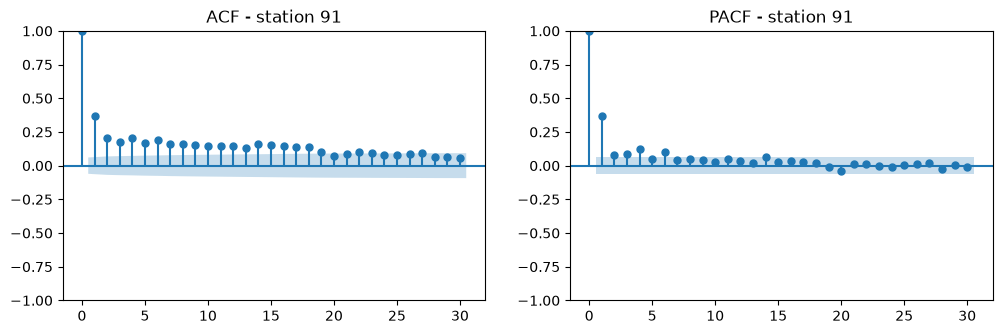

In [8]:
# acf pacf 
sid = t.sort_values("n_records").node_id.iloc[-1]
y = df[df.id == sid].drop_duplicates("datetime_utc").set_index("datetime_utc")["pm25"]
daily = y.reindex(pd.date_range(y.index.min(), y.index.max(), freq="D"))
run = longest_run(daily)
if len(run) < 30:
    run = y  # fallback: observed values in order
lags = min(30, len(run) // 2 - 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(run, lags=lags, ax=ax[0], title=f"ACF - station {sid}")
plot_pacf(run, lags=lags, ax=ax[1], title=f"PACF - station {sid}")
plt.show()

      median   iqr  pct_above_25
year                            
2016   10.17  7.06          1.80
2017    7.67  7.30          3.83
2018    7.02  6.17          0.40
2019    6.72  9.39          4.29
2020    5.71  6.56          2.06
2021    6.80  7.43          2.38
2022    8.12  7.36          2.02
2023    9.00  7.43          2.44
2024    8.00  6.93          3.15
2025    8.52  7.16          3.24
2026    6.77  9.75          7.30
       median   iqr  pct_above_25
month                            
1        8.15  8.90          4.85
2        9.25  9.39          6.62
3        7.26  7.58          4.00
4        6.44  5.87          1.30
5        6.87  5.72          0.82
6        7.81  7.09          1.90
7        8.30  6.92          1.31
8        9.36  7.85          2.64
9        7.00  5.96          1.39
10       7.80  7.14          2.46
11       7.91  8.11          3.59
12       8.91  9.60          7.05


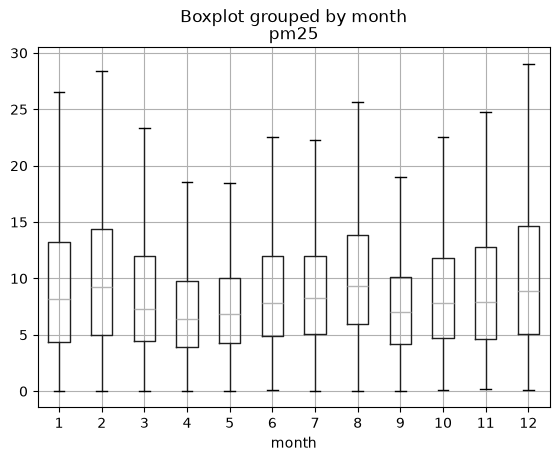

In [9]:
df["year"] = df.datetime_utc.dt.year
df["month"] = df.datetime_utc.dt.month

def summary(by):
    g = df.groupby(by)["pm25"]
    return pd.DataFrame({
        "median": g.median(),
        "iqr": g.quantile(0.75) - g.quantile(0.25),
        "pct_above_25": g.apply(lambda x: (x > 25).mean() * 100),
    }).round(2)

print(summary("year"))
print(summary("month"))
df.boxplot(column="pm25", by="month", showfliers=False)
plt.show()

In [10]:
preds = ["AOD", "NO2", "CO", "O3", "wind_u", "wind_v", "temperature_celsius"]
keep = t[t.n_records >= 100].node_id
rows = []
for sid, g in df[df.id.isin(keep)].groupby("id"):
    g = g.drop_duplicates("datetime_utc").set_index("datetime_utc")
    full = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq="D"))
    for p in preds:
        for k in range(8):
            rows.append((p, k, full["pm25"].corr(full[p].shift(k))))

lead_lag = (pd.DataFrame(rows, columns=["predictor", "lag_days", "corr"])
            .groupby(["predictor", "lag_days"])["corr"].mean().unstack().round(3))
lead_lag

lag_days,0,1,2,3,4,5,6,7
predictor,,,,,,,,
AOD,0.170,0.116,0.056,0.039,0.001,-0.009,-0.015,-0.023
CO,0.074,0.082,0.071,0.077,0.063,0.054,0.041,0.039
NO2,0.223,0.215,0.143,0.107,0.068,0.065,0.049,0.064
O3,-0.156,-0.164,-0.137,-0.112,-0.097,-0.096,-0.102,-0.087
temperature_celsius,0.015,0.000,-0.010,-0.016,-0.023,-0.016,-0.009,-0.015
wind_u,-0.189,-0.200,-0.169,-0.143,-0.087,-0.081,-0.042,-0.035
wind_v,0.102,0.073,0.013,-0.018,-0.021,-0.007,-0.013,-0.014
